SAMPLE SALES DATA
     month    product  units_sold  unit_price  unit_cost  discount_rate_pct  gross_sales  discount_amount    revenue  cost_of_goods  gross_profit  gross_margin_pct         period
2025-01-01     Laptop          38    61622.57   42389.75                5.0   2341657.72        117082.89 2224574.83     1610810.49     613764.34             27.59 First 6 Months
2025-01-01      Phone          81    29380.83   20711.04                5.0   2379847.52        118992.38 2260855.14     1677593.87     583261.27             25.80 First 6 Months
2025-01-01     Tablet          50    20439.41   14056.62                5.0   1021970.57         51098.53  970872.04      702831.22     268040.82             27.61 First 6 Months
2025-01-01    Monitor          46    14568.53   10187.96                5.0    670152.20         33507.61  636644.59      468646.34     167998.25             26.39 First 6 Months
2025-01-01 Headphones         127     2948.22    1480.91                5.0    374424.0

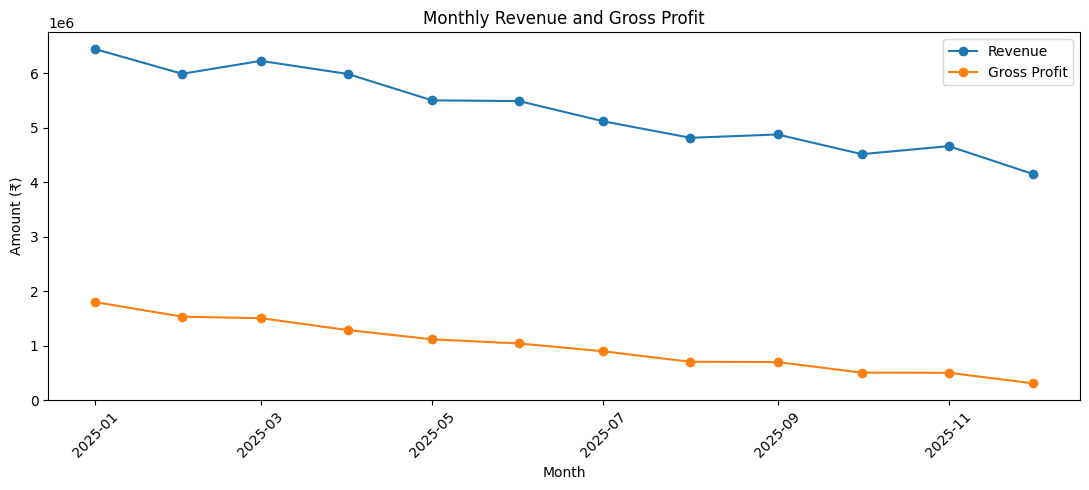

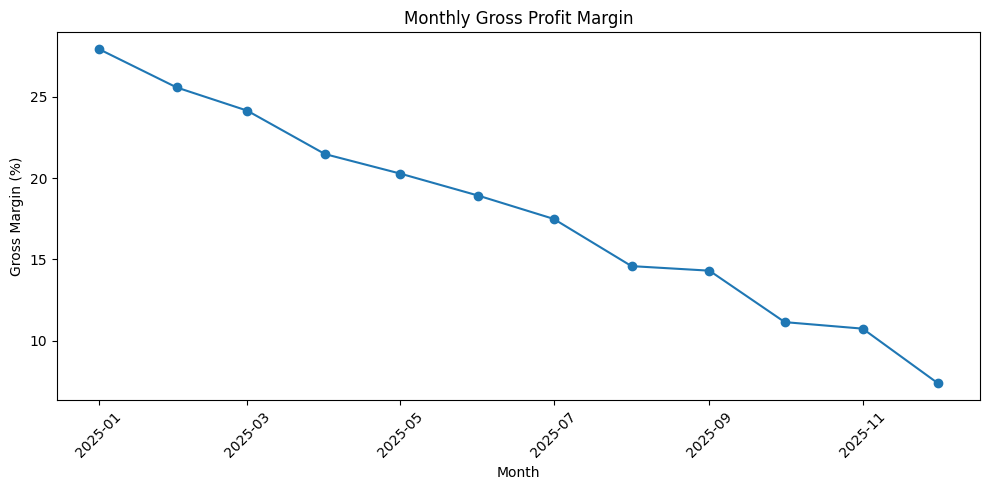


PRODUCT PROFITABILITY COMPARISON
   product  gross_profit_First_6_Months  gross_profit_Last_6_Months  profit_change_pct  margin_change_pp
Headphones                    825682.88                   528635.21             -35.98             -8.62
    Laptop                   2701347.14                  1062495.76             -60.67            -11.17
   Monitor                    917155.32                   375748.41             -59.03            -12.23
     Phone                   2598575.68                  1080916.24             -58.40             -9.61
    Tablet                   1234988.93                   561146.61             -54.56             -9.87


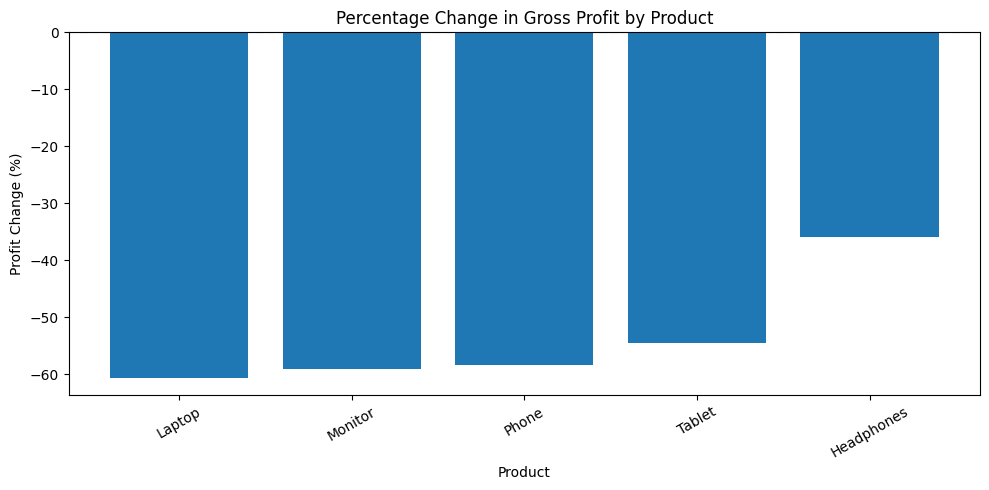


POTENTIAL PROFITABILITY DRIVERS
                average_discount_pct  average_unit_cost  average_unit_price  \
period                                                                        
First 6 Months                   7.0           18363.30            25527.58   
Last 6 Months                   11.8           19929.08            25657.43   

                total_discount  
period                          
First 6 Months      2662568.06  
Last 6 Months       3745002.35  


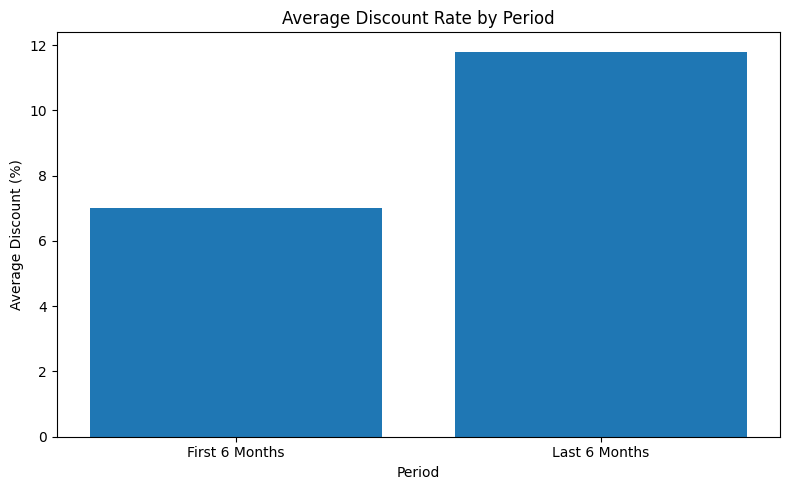


PRODUCTS WITH DECLINING GROSS PROFIT
   product  profit_change_pct  margin_change_pp
    Laptop             -60.67            -11.17
   Monitor             -59.03            -12.23
     Phone             -58.40             -9.61
    Tablet             -54.56             -9.87
Headphones             -35.98             -8.62

MANAGEMENT RECOMMENDATIONS
1. Investigate the decline in gross profit.
2. Total cost of goods did not increase.
3. Review discount policies and promotional effectiveness.
4. Investigate changes in demand and sales volume.
5. Review product-level performance for: Laptop, Monitor, Phone, Tablet, Headphones

Exported files:
- profitability_detailed_data.csv
- profitability_monthly_summary.csv
- profitability_product_comparison.csv

DISCLAIMER
This project uses synthetic sales and cost data.
The findings are illustrative, not actual company results.


In [1]:

# PROJECT 13: PROFITABILITY DECLINE INVESTIGATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. GENERATE SAMPLE BUSINESS DATA
# --------------------------------------------------

np.random.seed(42)

products = ["Laptop", "Phone", "Tablet", "Monitor", "Headphones"]
months = pd.date_range("2025-01-01", periods=12, freq="MS")

base_prices = {
    "Laptop": 60000,
    "Phone": 30000,
    "Tablet": 20000,
    "Monitor": 15000,
    "Headphones": 3000
}

base_costs = {
    "Laptop": 42000,
    "Phone": 21000,
    "Tablet": 14000,
    "Monitor": 10000,
    "Headphones": 1500
}

base_units = {
    "Laptop": 40,
    "Phone": 80,
    "Tablet": 55,
    "Monitor": 45,
    "Headphones": 120
}

records = []

for month_index, month in enumerate(months):
    for product in products:

        # Gradually increase operating costs
        cost_increase = 1 + 0.015 * month_index

        # Gradually increase discounting in later months
        discount_rate = min(
            0.05 + 0.008 * month_index,
            0.15
        )

        # Simulate a decline in sales volume over time
        volume_factor = 1 - 0.025 * month_index

        units_sold = max(
            1,
            int(
                base_units[product]
                * volume_factor
                * np.random.uniform(0.90, 1.10)
            )
        )

        unit_price = base_prices[product] * np.random.uniform(
            0.97, 1.03
        )

        unit_cost = base_costs[product] * cost_increase * np.random.uniform(
            0.98, 1.02
        )

        gross_sales = units_sold * unit_price
        discount_amount = gross_sales * discount_rate
        revenue = gross_sales - discount_amount
        cost_of_goods = units_sold * unit_cost

        records.append({
            "month": month,
            "product": product,
            "units_sold": units_sold,
            "unit_price": round(unit_price, 2),
            "unit_cost": round(unit_cost, 2),
            "discount_rate_pct": round(discount_rate * 100, 2),
            "gross_sales": round(gross_sales, 2),
            "discount_amount": round(discount_amount, 2),
            "revenue": round(revenue, 2),
            "cost_of_goods": round(cost_of_goods, 2)
        })

df = pd.DataFrame(records)

# --------------------------------------------------
# 2. CALCULATE PROFIT AND MARGIN
# --------------------------------------------------

df["gross_profit"] = df["revenue"] - df["cost_of_goods"]

df["gross_margin_pct"] = (
    df["gross_profit"] / df["revenue"] * 100
).round(2)

df["period"] = np.where(
    df["month"] < pd.Timestamp("2025-07-01"),
    "First 6 Months",
    "Last 6 Months"
)

print("SAMPLE SALES DATA")
print(df.head(10).to_string(index=False))

# --------------------------------------------------
# 3. COMPARE BUSINESS PERFORMANCE OVER TIME
# --------------------------------------------------

monthly = df.groupby("month", as_index=False).agg(
    revenue=("revenue", "sum"),
    cost_of_goods=("cost_of_goods", "sum"),
    gross_profit=("gross_profit", "sum"),
    units_sold=("units_sold", "sum"),
    discount_amount=("discount_amount", "sum")
)

monthly["gross_margin_pct"] = (
    monthly["gross_profit"] / monthly["revenue"] * 100
).round(2)

print("\nMONTHLY PERFORMANCE")
print(monthly.round(2).to_string(index=False))

# --------------------------------------------------
# 4. COMPARE FIRST 6 MONTHS WITH LAST 6 MONTHS
# --------------------------------------------------

period_summary = df.groupby("period").agg(
    revenue=("revenue", "sum"),
    cost_of_goods=("cost_of_goods", "sum"),
    gross_profit=("gross_profit", "sum"),
    units_sold=("units_sold", "sum"),
    discount_amount=("discount_amount", "sum")
)

period_summary["gross_margin_pct"] = (
    period_summary["gross_profit"]
    / period_summary["revenue"] * 100
)

print("\nPERIOD COMPARISON")
print(period_summary.round(2))

first = period_summary.loc["First 6 Months"]
last = period_summary.loc["Last 6 Months"]

def percentage_change(old, new):
    if old == 0:
        return np.nan
    return (new - old) / abs(old) * 100

print("\nCHANGE FROM FIRST 6 MONTHS TO LAST 6 MONTHS")
print(
    "Revenue change (%):",
    round(percentage_change(first["revenue"], last["revenue"]), 2)
)
print(
    "Cost change (%):",
    round(percentage_change(first["cost_of_goods"], last["cost_of_goods"]), 2)
)
print(
    "Gross profit change (%):",
    round(percentage_change(first["gross_profit"], last["gross_profit"]), 2)
)
print(
    "Units sold change (%):",
    round(percentage_change(first["units_sold"], last["units_sold"]), 2)
)
print(
    "Gross margin change (percentage points):",
    round(
        last["gross_margin_pct"] - first["gross_margin_pct"],
        2
    )
)

# --------------------------------------------------
# 5. VISUALIZE MONTHLY REVENUE AND PROFIT
# --------------------------------------------------

plt.figure(figsize=(11, 5))
plt.plot(
    monthly["month"],
    monthly["revenue"],
    marker="o",
    label="Revenue"
)
plt.plot(
    monthly["month"],
    monthly["gross_profit"],
    marker="o",
    label="Gross Profit"
)
plt.title("Monthly Revenue and Gross Profit")
plt.xlabel("Month")
plt.ylabel("Amount (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. VISUALIZE MONTHLY PROFIT MARGIN
# --------------------------------------------------

plt.figure(figsize=(10, 5))
plt.plot(
    monthly["month"],
    monthly["gross_margin_pct"],
    marker="o"
)
plt.title("Monthly Gross Profit Margin")
plt.xlabel("Month")
plt.ylabel("Gross Margin (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. IDENTIFY PRODUCT-LEVEL PROFITABILITY CHANGES
# --------------------------------------------------

product_period = df.groupby(
    ["product", "period"]
).agg(
    revenue=("revenue", "sum"),
    gross_profit=("gross_profit", "sum"),
    units_sold=("units_sold", "sum"),
    discount_amount=("discount_amount", "sum"),
    cost_of_goods=("cost_of_goods", "sum")
).reset_index()

product_period["gross_margin_pct"] = (
    product_period["gross_profit"]
    / product_period["revenue"] * 100
)

product_pivot = product_period.pivot(
    index="product",
    columns="period",
    values=["revenue", "gross_profit", "gross_margin_pct", "units_sold"]
)

product_pivot.columns = [
    f"{metric}_{period.replace(' ', '_')}"
    for metric, period in product_pivot.columns
]

product_pivot = product_pivot.reset_index()

product_pivot["profit_change_pct"] = (
    (
        product_pivot["gross_profit_Last_6_Months"]
        - product_pivot["gross_profit_First_6_Months"]
    )
    / product_pivot["gross_profit_First_6_Months"].abs()
    * 100
)

product_pivot["margin_change_pp"] = (
    product_pivot["gross_margin_pct_Last_6_Months"]
    - product_pivot["gross_margin_pct_First_6_Months"]
)

print("\nPRODUCT PROFITABILITY COMPARISON")
print(
    product_pivot[
        [
            "product",
            "gross_profit_First_6_Months",
            "gross_profit_Last_6_Months",
            "profit_change_pct",
            "margin_change_pp"
        ]
    ].round(2).to_string(index=False)
)

# --------------------------------------------------
# 8. CHART: PROFIT CHANGE BY PRODUCT
# --------------------------------------------------

product_sorted = product_pivot.sort_values("profit_change_pct")

plt.figure(figsize=(10, 5))
plt.bar(
    product_sorted["product"],
    product_sorted["profit_change_pct"]
)
plt.axhline(0, linestyle="--")
plt.title("Percentage Change in Gross Profit by Product")
plt.xlabel("Product")
plt.ylabel("Profit Change (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 9. INVESTIGATE DISCOUNTS AND COSTS
# --------------------------------------------------

driver_summary = df.groupby("period").agg(
    average_discount_pct=("discount_rate_pct", "mean"),
    average_unit_cost=("unit_cost", "mean"),
    average_unit_price=("unit_price", "mean"),
    total_discount=("discount_amount", "sum")
)

print("\nPOTENTIAL PROFITABILITY DRIVERS")
print(driver_summary.round(2))

plt.figure(figsize=(8, 5))
plt.bar(
    driver_summary.index,
    driver_summary["average_discount_pct"]
)
plt.title("Average Discount Rate by Period")
plt.xlabel("Period")
plt.ylabel("Average Discount (%)")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 10. FIND PRODUCTS WITH DECLINING PROFIT
# --------------------------------------------------

declining_products = product_pivot[
    product_pivot["profit_change_pct"] < 0
].sort_values("profit_change_pct")

print("\nPRODUCTS WITH DECLINING GROSS PROFIT")

if declining_products.empty:
    print("No products show a decline in gross profit.")
else:
    print(
        declining_products[
            [
                "product",
                "profit_change_pct",
                "margin_change_pp"
            ]
        ].round(2).to_string(index=False)
    )

# --------------------------------------------------
# 11. GENERATE MANAGEMENT RECOMMENDATIONS
# --------------------------------------------------

print("\nMANAGEMENT RECOMMENDATIONS")

if last["gross_profit"] < first["gross_profit"]:
    print("1. Investigate the decline in gross profit.")
else:
    print("1. Gross profit did not decline between the two periods.")

if last["cost_of_goods"] > first["cost_of_goods"]:
    print("2. Review supplier costs and product-level cost increases.")
else:
    print("2. Total cost of goods did not increase.")

if last["discount_amount"] > first["discount_amount"]:
    print("3. Review discount policies and promotional effectiveness.")
else:
    print("3. Total discount spending did not increase.")

if last["units_sold"] < first["units_sold"]:
    print("4. Investigate changes in demand and sales volume.")
else:
    print("4. Total units sold did not decline.")

if not declining_products.empty:
    products_list = ", ".join(
        declining_products["product"].tolist()
    )
    print("5. Review product-level performance for:", products_list)
else:
    print("5. Continue monitoring individual product profitability.")

# --------------------------------------------------
# 12. EXPORT ANALYSIS RESULTS
# --------------------------------------------------

df.to_csv("profitability_detailed_data.csv", index=False)
monthly.to_csv("profitability_monthly_summary.csv", index=False)
product_pivot.to_csv("profitability_product_comparison.csv", index=False)

print("\nExported files:")
print("- profitability_detailed_data.csv")
print("- profitability_monthly_summary.csv")
print("- profitability_product_comparison.csv")

print("\nDISCLAIMER")
print("This project uses synthetic sales and cost data.")
print("The findings are illustrative, not actual company results.")
